<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h1 style="color:#ffffff;margin:0;font-weight:normal;">4. Washing-machine disaggregation — estimate washing-machine power from the aggregate</h1></div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">1. Objective and data</h2></div>

**Objective:** estimate the power of the washing machine (W) from the whole-house **aggregate** power (W), one value per minute.

- **Household:** House 1. The readme lists `Appliance5` as the washing machine (Beko WMC6140). I chose House 1 from the six houses of notebook 3 because it has the longest record (551 valid days, 376 detected cycles) and a low share of `Issues`-flagged minutes (1.8%). The choice was made before any model was run.
- **Data:** the official cleaned file `CLEAN_House1.csv`, read only.
- **Input:** `Aggregate`. **Target:** `Appliance5`. Both are 1-minute mean power in W.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, f1_score

try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None
try:
    from lightgbm import LGBMRegressor
except ImportError:
    LGBMRegressor = None

sns.set_style("dark")
pd.options.display.float_format = "{:,.2f}".format

HOUSE, WM_CHANNEL = 1, 5
MAX_FILL = 5          # minutes: longest missing gap that is filled (as in notebook 3)
FROZEN_MIN = 30       # minutes: flat stretch of at least this length = suspected frozen (as in notebook 3)
ON_WATTS = 10         # a minute is "active" above this power (as in notebook 3)
MIN_ENERGY_WH = 1000  # relative energy error is only reported if the actual test energy is at least this

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">2. Preprocessing and split</h2></div>

Same preparation as `prepare_house` in notebook 3: 1-minute mean, gaps of 5 minutes or less filled, suspected-frozen stretches (30+ minutes) set to **missing**. Missing minutes stay missing (they are not 0 W) and are never used for training or testing. The official file is already forward-filled over outages (readme), so a long flat stretch can be a stalled logger and not real data; only stretches caught by the 30-minute rule are removed. The table after the features lists every exclusion.

In [2]:
def stretch_length(mask):
    run_id = (mask != mask.shift()).cumsum()
    return mask.groupby(run_id).transform("size") * mask

def fill_short_gaps(s, max_len=MAX_FILL):
    isna = s.isna()
    short = isna & (stretch_length(isna) <= max_len)
    return s.where(~short, s.ffill())

raw = pd.read_csv(f"../data/CLEAN_REFIT_081116/CLEAN_House{HOUSE}.csv")
channels = ["Aggregate"] + [f"Appliance{i}" for i in range(1, 10)]
minute = raw.set_index(pd.to_datetime(raw["Time"]))[channels + ["Issues"]].resample("1min").mean()
power = minute[channels].apply(fill_short_gaps)

previous = power.ffill()
steady = (previous["Aggregate"].diff() == 0) & (previous.drop(columns="Aggregate").diff().fillna(0) == 0).all(axis=1) & (power["Aggregate"] >= 10)
frozen = steady & (stretch_length(steady) >= FROZEN_MIN)

data = power[["Aggregate", f"Appliance{WM_CHANNEL}"]].rename(columns={f"Appliance{WM_CHANNEL}": "WM"})
data.loc[frozen] = np.nan                                  # excluded, not set to 0
issues = minute["Issues"] > 0                               # official flag: sub-meters add up to more than the aggregate (not a model input)
assert data.index.to_series().diff().dropna().eq(pd.Timedelta("1min")).all()     # one row per minute

**Features** use the current and **past** aggregate readings only, never future ones:
- `agg`: aggregate power now (the only input of Ridge).
- `lag1`, `lag2`, `lag5`: aggregate 1, 2 and 5 minutes ago, to show whether the power has just jumped.
- `mean15`: mean of the last 15 minutes (including now).
- `min30`: lowest value of the last 30 minutes (including now), a rough estimate of the always-on base load. `agg - min30` is what switched on above it.
- `delta`: aggregate power now minus 1 minute ago (`agg - lag1`). A sudden increase can show that an appliance has switched on.

A minute is **usable** if the target and all features are available.

In [3]:
a = data["Aggregate"]
features = pd.DataFrame({"agg": a, "lag1": a.shift(1), "lag2": a.shift(2), "lag5": a.shift(5),
                         "mean15": a.rolling(15, min_periods=15).mean(),          # NaN if any minute in the window is missing
                         "min30": a.rolling(30, min_periods=30).min(),
                         "delta": a - a.shift(1)})                                # change since the previous minute
FEATURES = list(features.columns)

usable = features.notna().all(axis=1) & data["WM"].notna()
d = features.join(data["WM"])[usable]

# alignment check: the lag columns really are the aggregate 1 / 5 minutes earlier
t = d.index[::5000]
for k in (1, 5):
    assert (d.loc[t, f"lag{k}"].to_numpy() == a.reindex(t - pd.Timedelta(minutes=k)).to_numpy()).all()
assert (d.loc[t, "delta"].to_numpy() == (a.reindex(t).to_numpy() - a.reindex(t - pd.Timedelta(minutes=1)).to_numpy())).all()

# what is excluded and why (every minute of the 1-minute table is in exactly one of the four groups)
no_reading = power["Aggregate"].isna()                                           # outages and gaps over 5 minutes, not filled
filled = minute["Aggregate"].isna() & power["Aggregate"].notna()                 # gaps of 5 minutes or less, filled with the last value
short_history = data["Aggregate"].notna() & data["WM"].notna() & ~usable         # valid minute, but a lag / rolling window is incomplete
assert no_reading.sum() + frozen.sum() + short_history.sum() + len(d) == len(data)
run_len = stretch_length(steady)
short_stall = (run_len >= 10) & (run_len < FROZEN_MIN)                           # all channels constant for 10-29 minutes: kept

pd.DataFrame({"household": f"House {HOUSE}", "first usable minute": d.index.min(), "last usable minute": d.index.max(),
              "resolution": "1 min", "input": "Aggregate (W)", "target": f"Appliance{WM_CHANNEL} (W)",
              "minutes in the 1-minute table": len(data),
              "excluded: no reading (outages, gaps over 5 min)": int(no_reading.sum()),
              "excluded: suspected frozen (30+ min flat)": int(frozen.sum()),
              "excluded: feature window incomplete": int(short_history.sum()),
              "usable minutes": len(d),
              "of which filled gaps (5 min or less)": int(filled.reindex(d.index).sum()),
              "of which constant for 10-29 min (kept)": int(short_stall.reindex(d.index).sum())}, index=["value"]).T

,value
household,House 1
first usable minute,2013-10-09 13:35:00
last usable minute,2015-07-10 11:56:00
resolution,1 min
input,Aggregate (W)
target,Appliance5 (W)
minutes in the 1-minute table,920091
"excluded: no reading (outages, gaps over 5 min)",115389
excluded: suspected frozen (30+ min flat),3019
excluded: feature window incomplete,11349


**Split:** chronological, 70% / 15% / 15% of the usable minutes, cut at timestamps. **Train** fits the models, **validation** chooses the settings and the model, and **test** is used once at the end. No minutes are mixed between the parts, and the features only look backwards (at earlier aggregate readings, never at targets), so the test targets never influence training. The test targets are not looked at before the final evaluation.

In [4]:
n = len(d)
i_train, i_val = int(0.70 * n), int(0.85 * n)
train, val, test = d.iloc[:i_train], d.iloc[i_train:i_val], d.iloc[i_val:]
assert train.index.max() < val.index.min() and val.index.max() < test.index.min()

def split_row(p, show_target):
    row = {"first minute": p.index.min(), "last minute": p.index.max(), "usable minutes": len(p)}
    if show_target:                                       # the test targets stay unseen until section 4
        row.update({"active minutes (> 10 W)": int((p["WM"] > ON_WATTS).sum()), "washing-machine energy (Wh)": p["WM"].sum() / 60})
    return row

pd.DataFrame({"train": split_row(train, True), "validation": split_row(val, True), "test": split_row(test, False)}).fillna("-")

,train,validation,test
first minute,2013-10-09 13:35:00,2014-12-28 04:41:00,2015-03-25 02:26:00
last minute,2014-12-28 04:40:00,2015-03-25 02:25:00,2015-07-10 11:56:00
usable minutes,553233,118550,118551
active minutes (> 10 W),10890,2345,-
washing-machine energy (Wh),"90,583.79","25,212.46",-


**Target quality.** The readme says the official file replaced appliance readings above 4,000 W by 0 W. This cell counts how many raw washing-machine readings that touches (the raw files are only read).

In [5]:
raw_wm = pd.concat([pd.read_csv(f"../data/REFIT_RAW_081116/RAW_House{HOUSE}_Part{k}.csv", usecols=["Unix", f"Appliance{WM_CHANNEL}"]) for k in (1, 2)])
over = raw_wm[raw_wm[f"Appliance{WM_CHANNEL}"] > 4000]
over_minutes = pd.Index(pd.to_datetime(over["Unix"], unit="s").dt.floor("min").unique())      # Time in the official file = Unix time (UTC)
affected = over_minutes.intersection(d.index)                                                  # usable minutes that contain such a reading
print(f"raw readings above 4,000 W: {len(over)} (largest {over[f'Appliance{WM_CHANNEL}'].max():,.0f} W; largest usable target {d['WM'].max():,.0f} W)")
print(f"usable minutes containing one: {len(affected)} of {len(d)} ({100 * len(affected) / len(d):.3f}%) | train {affected.isin(train.index).sum()}, validation {affected.isin(val.index).sum()}, test {affected.isin(test.index).sum()}")
print("official target in those minutes (W):", d.loc[affected, "WM"].round(1).value_counts().head(3).to_dict())

raw readings above 4,000 W: 221 (largest 73,725 W; largest usable target 2,462 W)
usable minutes containing one: 79 of 790334 (0.010%) | train 44, validation 18, test 17
official target in those minutes (W): {0.0: 65, 16.0: 9, 12.8: 1}


<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">3. Baseline and models</h2></div>

- **Always-off baseline:** predicts 0 W for every minute. The washing machine is off most of the time, so this rule already has a small error. A model is only useful if it does better than "always off" where it matters, which is when the machine runs.
- **Models:** Ridge (aggregate only), Random Forest, XGBoost and LightGBM (the last three use all seven features). Each has a small grid of settings. They are trained on **train** and the best setting of each is chosen on **validation** by RMSE.

In [6]:
def metrics(y, pred):
    pred = np.clip(pred, 0, None)                         # power cannot be negative
    return {"MAE (W)": mean_absolute_error(y, pred),
            "RMSE (W)": np.sqrt(mean_squared_error(y, pred)),
            "F1 (active > 10 W)": f1_score(y > ON_WATTS, pred > ON_WATTS, zero_division=0)}   # same threshold for actual and predicted

grids = {"Ridge": [(f"alpha={k}", make_pipeline(StandardScaler(), Ridge(alpha=k)), ["agg"]) for k in (0.1, 10, 1000)],
         "Random forest": [(f"min_samples_leaf={k}", RandomForestRegressor(n_estimators=50, min_samples_leaf=k, n_jobs=-1, random_state=0), FEATURES) for k in (10, 50)]}
if XGBRegressor is not None:
    grids["XGBoost"] = [(f"max_depth={k}", XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=k, n_jobs=-1, random_state=0), FEATURES) for k in (4, 6)]
if LGBMRegressor is not None:
    grids["LightGBM"] = [(f"num_leaves={k}", LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=k, n_jobs=-1, random_state=0, verbose=-1), FEATURES) for k in (15, 63)]
print("models not available:", [m for m, c in (("XGBoost", XGBRegressor), ("LightGBM", LGBMRegressor)) if c is None] or "none")

best = {}                                                 # model name -> (setting, fitted model, columns, validation scores)
for name, options in grids.items():
    for setting, model, cols in options:
        model.fit(train[cols], train["WM"])
        scores = metrics(val["WM"], model.predict(val[cols]))
        if name not in best or scores["RMSE (W)"] < best[name][3]["RMSE (W)"]:
            best[name] = (setting, model, cols, scores)

validation = pd.DataFrame({name: {"chosen setting": b[0], **b[3]} for name, b in best.items()}).T
validation.loc["Always off"] = ["-", *metrics(val["WM"], np.zeros(len(val))).values()]
validation

models not available: none


,chosen setting,MAE (W),RMSE (W),F1 (active > 10 W)
Ridge,alpha=0.1,23.56,150.09,0.10
Random forest,min_samples_leaf=10,18.96,124.91,0.20
XGBoost,max_depth=6,21.04,126.68,0.18
LightGBM,num_leaves=15,21.51,129.20,0.15
Always off,-,12.76,153.89,0.00


In [7]:
final_name = min(best, key=lambda m: best[m][3]["RMSE (W)"])       # chosen on validation only
print("model chosen on validation (lowest RMSE):", final_name)

model chosen on validation (lowest RMSE): Random forest


**Extra feature check.** `delta` was added to see whether it helps. The chosen setting of each tree model is refitted without it and both versions are compared on **validation** (the test period is not used).

In [8]:
rows = {}
for name, (setting, model, cols, scores) in best.items():
    if "delta" not in cols:
        continue                                           # Ridge only uses agg
    base_cols = [c for c in cols if c != "delta"]
    without = clone(model).fit(train[base_cols], train["WM"])
    rows[f"{name}, without delta"] = metrics(val["WM"], without.predict(val[base_cols]))
    rows[f"{name}, with delta (used)"] = scores
pd.DataFrame(rows).T

,MAE (W),RMSE (W),F1 (active > 10 W)
"Random forest, without delta",19.85,126.25,0.18
"Random forest, with delta (used)",18.96,124.91,0.20
"XGBoost, without delta",22.00,128.55,0.16
"XGBoost, with delta (used)",21.04,126.68,0.18
"LightGBM, without delta",21.76,129.58,0.14
"LightGBM, with delta (used)",21.51,129.20,0.15


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">delta</span> lowers the validation RMSE of all three tree models (random forest 126.3 W to 124.9 W, XGBoost 128.6 W to 126.7 W, LightGBM 129.6 W to 129.2 W) and also improves MAE and F1, so it is kept. The gain is small, about 1% for the random forest.</div>

**`Issues` flag.** The official flag marks minutes where the sub-meters add up to more than the aggregate. It is not a model input. Do flagged minutes make the target unreliable, and should they be removed? Checked on train and validation only.

In [9]:
# Issues flag check: train and validation only (the test period is not used for this decision)
fl = issues.reindex(d.index)
tv, tv_fl = d.iloc[:i_val], fl.iloc[:i_val]
active, heater = tv["WM"] > ON_WATTS, tv["WM"] >= 1000
over_agg = tv["WM"] > tv["agg"]                           # the target alone is larger than the aggregate
stats = pd.Series({"flagged minutes, all (%)": 100 * tv_fl.mean(),
                   "flagged minutes, machine off (%)": 100 * tv_fl[~active].mean(),
                   "flagged minutes, machine active > 10 W (%)": 100 * tv_fl[active].mean(),
                   "flagged minutes, heater on >= 1000 W (%)": 100 * tv_fl[heater].mean(),
                   "median target, heater minutes, flagged (W)": tv.loc[heater & tv_fl, "WM"].median(),
                   "median target, heater minutes, not flagged (W)": tv.loc[heater & ~tv_fl, "WM"].median(),
                   "minutes where the target is larger than the aggregate": int(over_agg.sum()),
                   "... of which flagged": int((over_agg & tv_fl).sum())})
display(stats.to_frame("train + validation"))

# would dropping flagged minutes from training help? scored on all validation minutes
setting, model, cols, _ = best[final_name]
keep = ~fl.loc[train.index]
refit = clone(model).fit(train.loc[keep, cols], train.loc[keep, "WM"])
val_ok = ~fl.loc[val.index].to_numpy()
print(f"heater minutes in training: {int((train['WM'] >= 1000).sum())}, of which flagged: {int(((train['WM'] >= 1000) & ~keep).sum())}")
rows = {}
for label, m in (("trained on all minutes (used)", model), ("trained without flagged minutes", refit)):
    pr = m.predict(val[cols])
    rows[label] = {**metrics(val["WM"], pr), "RMSE, unflagged validation minutes only (W)": metrics(val["WM"][val_ok], pr[val_ok])["RMSE (W)"]}
pd.DataFrame(rows).T

,train + validation
"flagged minutes, all (%)",2.13
"flagged minutes, machine off (%)",1.54
"flagged minutes, machine active > 10 W (%)",31.52
"flagged minutes, heater on >= 1000 W (%)",64.37
"median target, heater minutes, flagged (W)","2,262.37"
"median target, heater minutes, not flagged (W)","2,237.86"
minutes where the target is larger than the aggregate,699.00
... of which flagged,697.00


heater minutes in training: 1963, of which flagged: 1388


,MAE (W),RMSE (W),F1 (active > 10 W),"RMSE, unflagged validation minutes only (W)"
trained on all minutes (used),18.96,124.91,0.20,104.37
trained without flagged minutes,14.22,131.27,0.29,101.73


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;">The flag is rare overall (2.1% of minutes) but common while the machine runs: 31.5% of the active minutes and 64.4% of the heater minutes (1.5% when it is off). The target values in flagged heater minutes look normal (median 2,262 W, against 2,238 W when not flagged).</li>
<li style="margin-bottom:4px;">In 699 minutes (about 5% of the active minutes) the target is larger than the aggregate, and 697 of them are flagged. So the two sensors disagree in these minutes; I cannot tell which one is off.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Decision: keep the flagged minutes.</span> Removing them deletes 1,388 of the 1,963 heater minutes in the training period. Training without them gives a worse RMSE on all validation minutes (131.3 W against 124.9 W) but a better MAE and F1, so there is no clear gain. Scoring only the unflagged minutes would flatter the model (RMSE 104.4 W against 124.9 W), so the test period is scored on all minutes.</li></ul></div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">4. Evaluation</h2></div>

All models are scored on the untouched **test** period, with negative predictions clipped to 0 W.
- **MAE** and **RMSE** (W): average error. RMSE punishes large misses such as a missed heating burst (about 2.3 kW) much more than MAE.
- **F1**: how well the model finds the minutes when the machine is active (> 10 W, the same threshold for actual and predicted power).
- **Energy error (%)**: (predicted − actual) / actual energy over the whole test period, with energy = sum of the 1-minute powers / 60 (Wh), over the usable test minutes only (missing minutes are left out, not counted as 0 W). It is shown only if the actual test energy is at least 1,000 Wh; it can hide errors that cancel out over time.

In [10]:
def energy_error(y, pred):
    actual_wh = y.sum() / 60
    return 100 * (np.clip(pred, 0, None).sum() / 60 - actual_wh) / actual_wh if actual_wh >= MIN_ENERGY_WH else np.nan

predictions = {"Always off": pd.Series(0.0, index=test.index)}
for name, (setting, model, cols, _) in best.items():
    predictions[name] = pd.Series(np.clip(model.predict(test[cols]), 0, None), index=test.index)

results = pd.DataFrame({name: {**metrics(test["WM"], p), "energy error (%)": energy_error(test["WM"], p)} for name, p in predictions.items()}).T
results

,MAE (W),RMSE (W),F1 (active > 10 W),energy error (%)
Always off,10.71,134.62,0.00,-100.00
Ridge,17.48,131.75,0.21,-27.17
Random forest,12.46,97.03,0.33,16.94
XGBoost,13.83,97.71,0.31,23.09
LightGBM,14.12,100.17,0.26,17.95


<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">5. Actual versus predicted power</h2></div>

The plot shows the chosen model on the test period. **Window rule** (does not use the predictions): split the test period into consecutive 48-hour blocks, keep the blocks with every minute observed and some washing-machine activity, and take the block in the middle when the blocks are sorted by actual washing-machine energy (the median).

11 eligible 48-hour blocks; median block starts 2015-05-21 00:00:00 (822 Wh)


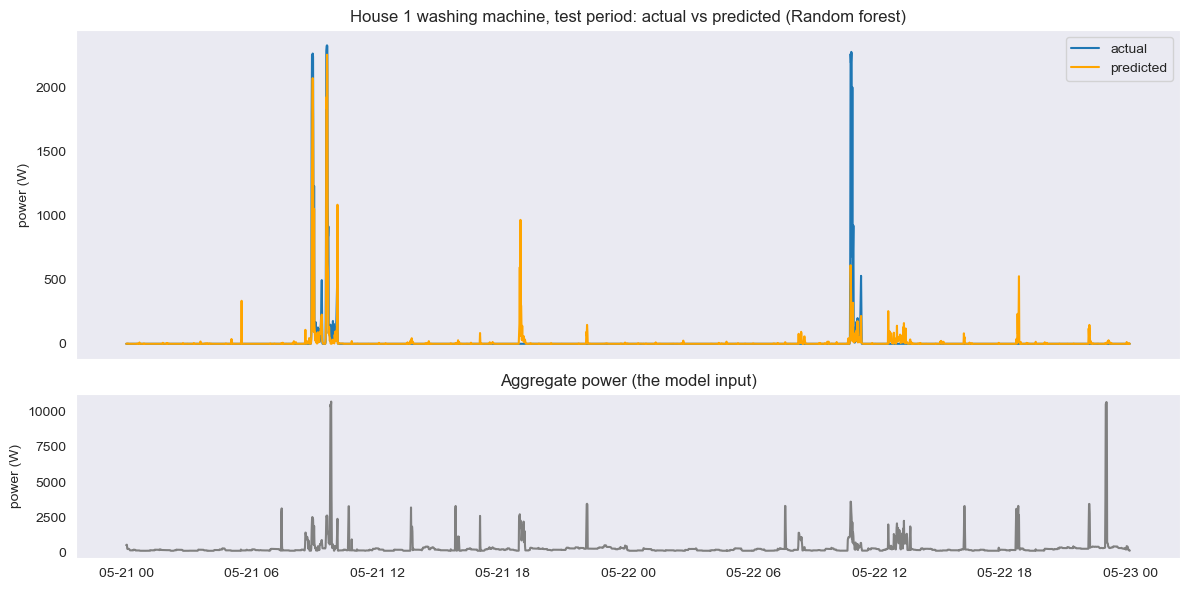

In [11]:
span = pd.Timedelta(minutes=2879)                         # 48 hours = 2,880 minutes
blocks, start = [], test.index.min().ceil("D")
while start + span <= test.index.max():
    w = test.loc[start:start + span]
    if len(w) == 2880 and (w["WM"] > ON_WATTS).any():
        blocks.append((start, w["WM"].sum() / 60))
    start += pd.Timedelta(hours=48)
blocks = pd.DataFrame(blocks, columns=["start", "actual energy (Wh)"]).sort_values("actual energy (Wh)").reset_index(drop=True)
plot_start = blocks.loc[len(blocks) // 2, "start"]
print(f"{len(blocks)} eligible 48-hour blocks; median block starts {plot_start} ({blocks.loc[len(blocks) // 2, 'actual energy (Wh)']:.0f} Wh)")

w = test.loc[plot_start:plot_start + span]
assert len(w) == 2880 and w.index.to_series().diff().dropna().eq(pd.Timedelta("1min")).all()      # 48 h, every minute observed
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 6), gridspec_kw={"height_ratios": [2, 1]})
sns.lineplot(x=w.index, y=w["WM"], label="actual", ax=axes[0])
sns.lineplot(x=w.index, y=predictions[final_name].loc[w.index], label="predicted", color="orange", ax=axes[0])
axes[0].set(title=f"House {HOUSE} washing machine, test period: actual vs predicted ({final_name})", ylabel="power (W)", xlabel="")
sns.lineplot(x=w.index, y=w["agg"], color="gray", ax=axes[1])
axes[1].set(title="Aggregate power (the model input)", ylabel="power (W)", xlabel="")
plt.tight_layout()
plt.show()

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">6. Findings and limitations</h2></div>

In [12]:
# numbers for the failure cases (test period, chosen model)
y, p = test["WM"], predictions[final_name]
heater = y >= 1000                                        # minutes with the heating element on
ts = y.index[heater].to_series()
burst = (ts.diff() > pd.Timedelta("15min")).cumsum()      # heater minutes less than 15 minutes apart = one burst
burst_peak = p[heater].groupby(burst.to_numpy()).max()          # highest prediction inside each burst
actual_peak = y[heater].groupby(burst.to_numpy()).max()         # highest actual power inside each burst
off = y <= ON_WATTS
false_alarm = off & (p > ON_WATTS)
big_false_alarm = off & (p >= 500)

# the two examples named in the findings, taken from the plotted 48-hour window `w`
off_w = w["WM"] <= ON_WATTS
t_fa = p.loc[w.index][off_w].idxmax()
print(f"plotted window, largest false alarm: {t_fa:%Y-%m-%d %H:%M}, predicted {p[t_fa]:.0f} W, aggregate {w.loc[t_fa, 'agg']:.0f} W")
b_in = burst[burst.index.isin(w.index)]                                        # heating bursts inside the window
worst = (p.loc[b_in.index].groupby(b_in).max() / y.loc[b_in.index].groupby(b_in).max()).idxmin()
sel = b_in[b_in == worst].index
print(f"plotted window, worst heating burst ({sel.min():%Y-%m-%d %H:%M}): actual max {y.loc[sel].max():.0f} W, predicted max {p.loc[sel].max():.0f} W")

pd.Series({
    "heater bursts in test": len(burst_peak),
    "bursts where the model reaches 500 W": int((burst_peak >= 500).sum()),
    "median predicted power in heater minutes (W)": p[heater].median(),
    "median predicted burst peak as % of the actual burst peak": 100 * (burst_peak / actual_peak).median(),
    "off minutes in test": int(off.sum()),
    "off minutes predicted above 10 W": int(false_alarm.sum()),
    "off minutes predicted at 500 W or more": int(big_false_alarm.sum()),
    "median aggregate in those minutes (W)": test.loc[big_false_alarm, "agg"].median(),
    "largest prediction while off (W)": p[off].max(),
    "aggregate in that minute (W)": test.loc[p[off].idxmax(), "agg"],
    "precision (active > 10 W)": ((y > ON_WATTS) & (p > ON_WATTS)).sum() / (p > ON_WATTS).sum(),
    "recall (active > 10 W)": ((y > ON_WATTS) & (p > ON_WATTS)).sum() / (y > ON_WATTS).sum(),
})

plotted window, largest false alarm: 2015-05-21 18:51, predicted 966 W, aggregate 2298 W
plotted window, worst heating burst (2015-05-22 10:38): actual max 2276 W, predicted max 612 W


heater bursts in test                                            75.00
bursts where the model reaches 500 W                             70.00
median predicted power in heater minutes (W)                    990.16
median predicted burst peak as % of the actual burst peak        84.41
off minutes in test                                         115,998.00
off minutes predicted above 10 W                              8,889.00
off minutes predicted at 500 W or more                          309.00
median aggregate in those minutes (W)                         2,509.00
largest prediction while off (W)                              2,280.68
aggregate in that minute (W)                                  2,561.33
precision (active > 10 W)                                         0.20
recall (active > 10 W)                                            0.89
dtype: float64

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Results (test period, models trained on the training period only)</span>
<ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">Random forest</span> was chosen on validation RMSE (124.9 W). On the test period it has the lowest RMSE (97.0 W, against 134.6 W for always-off) and the highest F1 (0.33, against 0.00), but not the lowest MAE (see below). XGBoost (97.7 W) and LightGBM (100.2 W) are close in RMSE. Ridge, which only sees the current aggregate power, is barely better than always-off in RMSE (131.8 W).</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">MAE does not agree.</span> Always-off has the lowest MAE (10.7 W; random forest 12.5 W) because the machine is off in about 98% of the test minutes, so every small wrong prediction adds error. No model beats the baseline on MAE. The models are better at finding the heating bursts, which always-off misses completely, so I compare RMSE, F1 and energy together and not one metric alone.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Energy:</span> the random forest overestimates the test energy by 17% (LightGBM +18%, XGBoost +23%, Ridge −27%). Over- and under-prediction cancel over time, so this does not mean every cycle is right.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">F1 is low</span> mainly because of false alarms: precision is 0.20 and recall is 0.89. These scores measure whether activity is detected; they do not show that the power is reproduced minute by minute (see failure case 2).</li></ul></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Failure cases (observed in the test period, random forest)</span>
<ol style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">Another load at a similar power.</span> 8,889 of the 115,998 minutes with the machine off (7.7%) are predicted above 10 W, and 309 of them at 500 W or more, where the median aggregate is about 2.5 kW. So some other load of about that size is running while the machine is off, and the model, which only sees the aggregate, cannot tell it from the washing-machine heater. I did not identify which appliance it is. The largest false alarm is 2,281 W while the aggregate is 2,561 W. In the plot, at 18:51 on 21 May the model predicts 966 W while the machine is off and the aggregate is 2,298 W.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Cycle stages: finding a burst is not the same as reconstructing it.</span> 70 of the 75 heating bursts of the test period are found (the prediction reaches 500 W at some minute; 500 W is my choice), and the highest prediction inside a burst is a median 84% of the actual burst peak. But the power profile inside the bursts is not reproduced: in the minutes where the machine really uses 1,000 W or more, the median prediction is only 990 W (the actual power is about 2.3 kW). In the plot, the burst on 22 May is predicted at most 612 W against 2,276 W actual. The low-power parts of a cycle are small compared with the base load of the house (about 200 W in the plot), so I expect the model to struggle there too (not measured separately).</li></ol></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Limitations</span>
<ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">One household,</span> so nothing is shown about other houses or other washing machines.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">One test period,</span> with no uncertainty estimate. Validation is winter and test is spring to summer 2015, so the usage may differ.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Only current and past readings</span> are used. A model that also sees the following minutes (as in Seq2Point) would probably recognise the shape of a cycle better. I did not test this.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Data:</span> the official files are forward-filled over outages. Suspected frozen stretches (30+ minutes) are excluded; 372 usable minutes (0.05%) where all channels are constant for 10–29 minutes are kept. The official file replaced readings above 4,000 W by 0 W, which touches 79 usable minutes (0.010%, 17 of them in the test period); I cannot recover the true values, and removing those 17 test minutes changes no test metric by more than 0.01 W (checked separately). <span style="color:#0A6E68;">Issues</span>-flagged minutes are kept (see section 3), but in about 5% of the active minutes the target is larger than the aggregate, and I cannot tell which sensor is wrong.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Limited tuning:</span> the chosen setting is at the edge of its small grid for the random forest, XGBoost and LightGBM, so a wider search might change the results. I did not try one.</li></ul></div>